# Turnover precoce: quem sai antes dos 60 dias?

Em uma operação logística, boa parte das saídas acontece no período de experiência. Esta análise acompanha cada contratado desde a admissão e mede quem saiu em até 60 dias, por turno, área, idade e cargo.

**Os dados são fictícios** (gerados por `gerar_dados_sinteticos.py`). O método é o mesmo que usei em uma análise real de RH.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("dados/admitidos_sinteticos.csv", sep=";", parse_dates=["data_admissao", "data_desligamento"])
df.head()

,id,data_admissao,data_desligamento,cargo,area,turno,idade,genero
0,C0001,2026-08-17,2026-09-17,Auxiliar de Operação,Medicamentos,Diurno,25,Masculino
1,C0002,2026-06-02,2026-06-15,Auxiliar de Operação,Higiene e Beleza,Noturno,41,Masculino
2,C0003,2026-06-16,NaT,Operador de Empilhadeira,Medicamentos,Diurno,34,Feminino
3,C0004,2026-08-06,2026-09-03,Auxiliar de Operação,Higiene e Beleza,Diurno,30,Feminino
4,C0005,2026-05-22,2026-05-31,Auxiliar de Operação,Higiene e Beleza,Diurno,25,Masculino


## 1. Montar a coorte

Só entram admitidos até 31/08, para que todos tenham tido 60 dias para sair ou ficar até a data de corte (31/10).

In [2]:
corte = pd.Timestamp("2026-10-31")
coorte = df[df["data_admissao"] <= "2026-08-31"].copy()
coorte["dias_ate_sair"] = (coorte["data_desligamento"] - coorte["data_admissao"]).dt.days
coorte["saiu_ate_60d"] = coorte["dias_ate_sair"] <= 60

print(f"Contratados na coorte: {len(coorte)}")
print(f"Saíram em até 60 dias: {coorte['saiu_ate_60d'].sum()} ({coorte['saiu_ate_60d'].mean():.0%})")

Contratados na coorte: 800
Saíram em até 60 dias: 358 (45%)


## 2. Taxa de saída em até 60 dias por perfil

In [3]:
coorte["faixa_idade"] = pd.cut(coorte["idade"], [17, 24, 29, 34, 44, 99],
                               labels=["18-24", "25-29", "30-34", "35-44", "45+"])

def taxa(col):
    t = coorte.groupby(col, observed=True)["saiu_ate_60d"].agg(contratados="size", taxa="mean")
    t["taxa"] = (t["taxa"] * 100).round(1)
    return t.sort_values("taxa", ascending=False)

for col in ["turno", "area", "faixa_idade", "cargo"]:
    print(taxa(col), "\n")

         contratados  taxa
turno                     
Noturno          304  57.9
Diurno           496  36.7 

                  contratados  taxa
area                               
Higiene e Beleza          353  51.3
Medicamentos              447  39.6 

             contratados  taxa
faixa_idade                   
25-29                179  50.8
35-44                191  45.0
45+                   29  44.8
30-34                203  44.3
18-24                198  39.4 

                          contratados  taxa
cargo                                      
Auxiliar de Operação              627  47.2
Conferente                        109  45.0
Operador de Empilhadeira           64  20.3 



## 3. Turno e área juntos

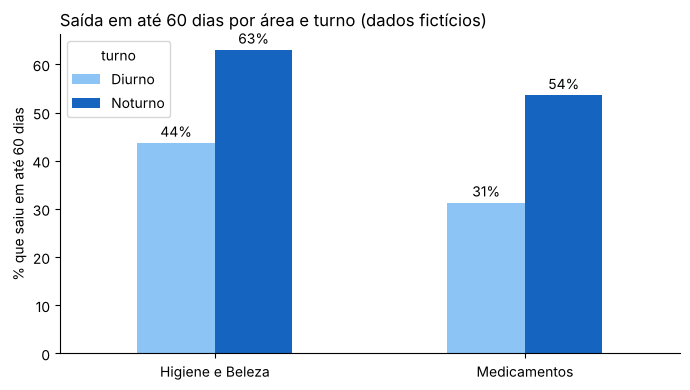

In [4]:
cruz = coorte.pivot_table(index="area", columns="turno", values="saiu_ate_60d", aggfunc="mean") * 100

ax = cruz.plot(kind="bar", color=["#8CC4F5", "#1565C0"], figsize=(7, 4), rot=0)
ax.set_ylabel("% que saiu em até 60 dias")
ax.set_xlabel("")
ax.set_title("Saída em até 60 dias por área e turno (dados fictícios)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%", padding=2)
plt.tight_layout()
plt.savefig("imagens/area_turno.png", dpi=150)
plt.show()

## 4. Curva de permanência nos primeiros 90 dias

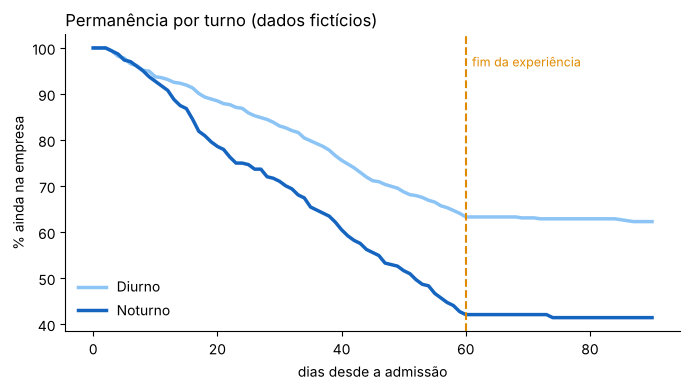

In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for turno, cor in [("Diurno", "#8CC4F5"), ("Noturno", "#1565C0")]:
    g = coorte[coorte["turno"] == turno]
    dias = range(0, 91)
    ficou = [((g["dias_ate_sair"].isna()) | (g["dias_ate_sair"] > d)).mean() * 100 for d in dias]
    ax.plot(dias, ficou, color=cor, linewidth=2.5, label=turno)
ax.axvline(60, color="#E08A00", linestyle="--", linewidth=1.5)
ax.text(61, 96, "fim da experiência", color="#E08A00", fontsize=9)
ax.set_xlabel("dias desde a admissão")
ax.set_ylabel("% ainda na empresa")
ax.set_title("Permanência por turno (dados fictícios)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.savefig("imagens/permanencia_turno.png", dpi=150)
plt.show()

## 5. O que eu faria com isso

- **Recrutar com foco no perfil que fica**: onde a taxa é menor, a vaga fecha com menos retrabalho.
- **Acompanhar os primeiros 60 dias**: um formulário curto do líder aos 15, 30 e 45 dias, cruzado com o motivo de saída, para agir antes do desligamento.
- **Olhar o turno noturno de perto**: é onde a curva cai mais rápido.

Os percentuais acima vêm de dados sorteados; na base real, as conclusões foram apresentadas à gestão como apoio ao plano de contratação.